In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [ ]:
diamonds = sns.load_dataset('diamonds')


In [ ]:
print(diamonds.head())
print(diamonds.info())


   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float6

Pré-processamento dos Dados:

Converter variáveis categóricas em numéricas usando get_dummies()

In [ ]:
diamonds_encoded = pd.get_dummies(diamonds, drop_first=True)


Definir Variáveis Independentes e Dependentes:

Vamos prever o preço (price) baseado em algumas características.

In [ ]:
X = diamonds_encoded.drop('price', axis=1)
y = diamonds_encoded['price']


Dividir os Dados em Conjuntos de Treinamento e Teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Criar e Treinar o Modelo de Regressão Linear

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

Prever os Valores e Avaliar o Modelo

In [ ]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'R²: {r2}')


R²: 0.9189331350419387


Visualizar os Resultados

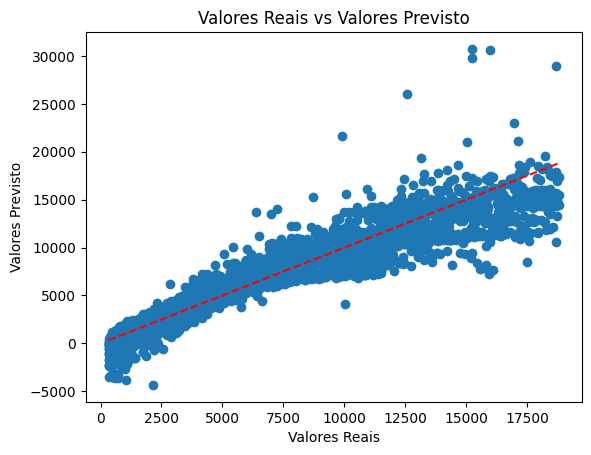

In [ ]:
plt.scatter(y_test, y_pred)
plt.xlabel('Valores Reais')
plt.ylabel('Valores Previsto')
plt.title('Valores Reais vs Valores Previsto')
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--r')
plt.show()


APLICAÇÃO DO ANOVA

In [ ]:
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols


In [ ]:
diamonds = sns.load_dataset('diamonds')


In [ ]:
print(diamonds.head())


   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75


Realizar ANOVA:

Usaremos o modelo linear para ajustar a relação entre o preço e a variável "cut"

In [ ]:
model = ols('price ~ C(cut)', data=diamonds).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)


                sum_sq       df           F         PR(>F)
C(cut)    1.104175e+10      4.0  175.688717  8.428307e-150
Residual  8.474314e+11  53935.0         NaN            NaN


Se o p-valor for menor que 0.05 (ou o nível de significância que você escolher), concluimos que há diferenças significativas nos preços dos diamantes entre os diferentes tipos de corte.

In [ ]:
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Carregar a base de dados
diamonds = sns.load_dataset('diamonds')

# Visualizar os dados
print(diamonds.head())

# Realizar ANOVA
model = ols('price ~ C(cut)', data=diamonds).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

# Interpretação
if anova_table['PR(>F)'][0] < 0.05:
    print("Há diferenças significativas entre os preços dos diamantes com base no tipo de corte.")
else:
    print("Não há diferenças significativas entre os preços dos diamantes com base no tipo de corte.")


   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
                sum_sq       df           F         PR(>F)
C(cut)    1.104175e+10      4.0  175.688717  8.428307e-150
Residual  8.474314e+11  53935.0         NaN            NaN
Há diferenças significativas entre os preços dos diamantes com base no tipo de corte.


<ipython-input-14-91d388b0b63e>:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if anova_table['PR(>F)'][0] < 0.05:


In [ ]:
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Carregar a base de dados
diamonds = sns.load_dataset('diamonds')

# Realizar ANOVA
model = ols('price ~ C(cut)', data=diamonds).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

# Interpretação
if anova_table['PR(>F)'][0] < 0.05:
    print("Há diferenças significativas entre os preços dos diamantes com base no tipo de corte.")
else:
    print("Não há diferenças significativas entre os preços dos diamantes com base no tipo de corte.")


                sum_sq       df           F         PR(>F)
C(cut)    1.104175e+10      4.0  175.688717  8.428307e-150
Residual  8.474314e+11  53935.0         NaN            NaN
Há diferenças significativas entre os preços dos diamantes com base no tipo de corte.


<ipython-input-15-e440933e2fc9>:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if anova_table['PR(>F)'][0] < 0.05:


Determinação coeficiente de correlação

In [ ]:
import pandas as pd


In [ ]:
# Exemplo de dados
data = {
    'horas_estudo': [1, 2, 3, 4, 5],
    'nota_matematica': [50, 60, 70, 80, 90]
}
df = pd.DataFrame(data)


In [ ]:
correlacao = df['horas_estudo'].corr(df['nota_matematica'])





print(f'Coeficiente de Correlação: {correlacao}')


Coeficiente de Correlação: 1.0


In [ ]:
# Exemplo com um DataFrame maior
df_maior = pd.DataFrame({
    'horas_estudo': [1, 2, 3, 4, 5],
    'nota_matematica': [50, 60, 70, 80, 90],
    'nota_portugues': [55, 65, 75, 85, 95]
})

# Calcular a matriz de correlação
matriz_correlacao = df_maior.corr()
print(matriz_correlacao)


                 horas_estudo  nota_matematica  nota_portugues
horas_estudo              1.0              1.0             1.0
nota_matematica           1.0              1.0             1.0
nota_portugues            1.0              1.0             1.0
